# 2.3 Python 实验

依据手稿整理；虚构数据。请选择 myenv 或安装了依赖的 Python 内核，从头顺序运行。图片保存到工作目录下的“图片”文件夹。

每个代码块与 PDF 中的编号一一对应。网页复制按钮只复制代码，不在网页执行。

## 2.3.1 开始使用（Getting Started）


### 代码 2.3.1-01：检查环境并准备图片目录

`import` 导入工具，`as np` 是给 NumPy 起常用别名。`Path` 表示文件路径，`mkdir(exist_ok=True)` 表示目录已存在时不报错。版本号说明这份输出在哪个软件环境产生；其他环境的显示细节可能略有不同。

### 逐步读代码

- 每条`import`把一个工具模块载入当前内核；`np`、`pd`、`plt`是常用别名，`sklearn`是scikit-learn的导入名。

- `Path("图片")`创建路径对象，不会立刻创建文件夹；接着的`mkdir(exist_ok=True)`才创建目录，并允许它已存在。

- `sys.version`是一段版本说明字符串，`.split()`按空白拆开，`[0]`取第一段。各库的`__version__`是版本字符串；打印它们便于复现环境。

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

image_dir = Path("图片")
image_dir.mkdir(exist_ok=True)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.10.20
NumPy: 2.2.6
pandas: 2.3.3
Matplotlib: 3.10.8
scikit-learn: 1.7.2


### 练习 2.24  重启后为什么出现 NameError？

单独运行使用 $X$ 的单元格，提示变量未定义，应该怎么办？


**参考答案**

先运行定义 $X$ 的单元格；若不确定变量状态，重启内核后从头运行。Notebook 的屏幕顺序不等于曾经执行的顺序。



## 2.3.2 基本命令（Basic Commands）


### 代码 2.3.2-01：列表相加与重复

`a + b` 把两个列表首尾连接；`a * 2` 把列表内容重复两次。它们没有计算向量的逐元素和或数乘。

### 逐步读代码

- 方括号创建Python列表，逗号分隔元素；`a`和`b`各包含三个整数。

- 列表的`+`表示连接，所以得到六个元素；列表乘整数表示重复，`a*2`是把整个列表重复两遍。`print`展示结果，并没有把它重新赋给`a`。

In [3]:
a = [1, 2, 3]
b = [10, 20, 30]
print(a + b)
print(a * 2)


[1, 2, 3, 10, 20, 30]
[1, 2, 3, 1, 2, 3]


### 练习 2.25  列表乘法

`[2, 4] * 2` 会得到什么？为什么不是两个元素分别翻倍？


**参考答案**

结果是 `[2, 4, 2, 4]`。列表的乘法表示重复；数值逐元素乘法需要使用数值数组。



## 2.3.3 NumPy 入门（Introduction to Numerical Python）


### 代码 2.3.3-01：数组的逐元素运算

`np.array` 创建数组，`dtype=float` 指定浮点数。这里两个数组形状相同，`+` 把对应位置相加，`* 2` 把每个数乘二，`** 2` 把每个数平方。

### 逐步读代码

- `dtype=float`要求数组元素用浮点类型保存，适合后续小数运算。

- 数组的`a+b`按对应位置相加；`a*2`逐元素翻倍；`a**2`逐元素平方。这里的`**`是乘方，不是乘法。

In [4]:
a = np.array([1, 2, 3], dtype=float)
b = np.array([10, 20, 30], dtype=float)
print(a + b)
print(a * 2)
print(a ** 2)


[11. 22. 33.]
[2. 4. 6.]
[1. 4. 9.]


### 代码 2.3.3-02：业务数据：行是样本，列是特征

沿用广告预算例子：三行代表三个市场，两列代表两种广告投入。`shape` 是各轴长度，因此为 $(3,2)$；`ndim` 是轴的个数，为 $2$；`size` 是元素总数，为 $3\times2=6$；`dtype` 是元素类型。

### 逐步读代码

- 最外层列表有三项，每项又包含两个数，所以数组有三行两列；三行代表三个市场，两列代表两种预算。

- `shape`给出各轴长度`(3,2)`；`ndim`给出轴数2；`size`给出元素总数6；`dtype`给出元素类型。它们都是属性，读取时不用写括号。

In [5]:
X = np.array([
    [100.0, 20.0],
    [150.0, 10.0],
    [80.0, 30.0],
])
print(X)
print(X.shape)
print(X.ndim)
print(X.size)
print(X.dtype)


[[100.  20.]
 [150.  10.]
 [ 80.  30.]]
(3, 2)
2
6
float64


### 代码 2.3.3-03：一维数组、列矩阵与行矩阵

$(3,)$ 只有一个轴，没有显式的行、列方向。$(3,1)$ 是三行一列，$(1,3)$ 是一行三列。`.T` 交换二维矩阵的行列；一维数组转置后仍是一维数组。

### 逐步读代码

- `v`是一维数组，形状`(3,)`；`column`每行一个数，形状`(3,1)`；`row`只有一行，形状`(1,3)`。

- `.T`表示转置。一维数组只有一个轴，转置后仍为`(3,)`；二维列数组转置后才成为`(1,3)`。不能用一维数组的转置来制造列向量。

In [6]:
v = np.array([10.0, 20.0, 30.0])
column = np.array([[10.0], [20.0], [30.0]])
row = np.array([[10.0, 20.0, 30.0]])
print(v.shape, column.shape, row.shape)
print(v.T.shape, column.T.shape)


(3,) (3, 1) (1, 3)
(3,) (1, 3)


### 代码 2.3.3-04：reshape 改变形状

`reshape` 改变形状，元素总数不变。`-1` 让 NumPy 根据元素总数与其他维度自动计算这一维；一次最多有一个 `-1`。这里原来的 `v.shape` 仍为 $(3,)$：调用后返回的新形状数组需要赋给变量。

### 逐步读代码

- `reshape(3,1)`和`reshape(1,3)`重新组织同样三个元素，分别返回列形状和行形状；元素总数必须保持一致。

- `reshape(-1,1)`只指定一列，行数自动计算；`reshape(-1)`把数组展为一维。代码把返回对象赋给新名字，所以最后的`v.shape`仍是`(3,)`。

In [7]:
column = v.reshape(3, 1)
row = v.reshape(1, 3)
print(column)
print(row)
column_auto = v.reshape(-1, 1)
flat = column_auto.reshape(-1)
print(column_auto.shape)
print(flat.shape)
print(v.shape)


[[10.]
 [20.]
 [30.]]
[[10. 20. 30.]]
(3, 1)
(3,)
(3,)


### 代码 2.3.3-05：逐元素乘法与矩阵乘法

`X * beta` 将两列分别乘以两个系数，保留每项贡献，结果形状为 $(3,2)$。这利用广播：形状 $(2,)$ 的系数沿每行应用。`X @ beta` 再把每行两项加起来，得到三个预测贡献之和，形状为 $(3,)$。截距 $5$ 加到每个结果上。

$$\widehat y_i=5+0.04X_{i1}+0.10X_{i2}.$$

第一行是 $5+0.04\times100+0.10\times20=11$，其余两行同样计算。

### 逐步读代码

- `beta`按特征列顺序保存两个系数。`X*beta`通过广播把每行的两个特征分别乘对应系数，结果仍为`(3,2)`，每格是一个特征的贡献。

- `X @ beta`执行矩阵与向量乘法，把每行贡献加起来，返回`(3,)`。再加标量截距5时，5会加到每个预测上。

- `y_pred`每个元素对应一个市场，预测数量由样本行数决定，不由系数数量决定。

In [8]:
beta = np.array([0.04, 0.10])
contributions = X * beta
print(contributions)
print(X @ beta)
intercept = 5.0
y_pred = intercept + X @ beta
print(y_pred)
print(y_pred.shape)


[[4.  2. ]
 [6.  1. ]
 [3.2 3. ]]
[6.  7.  6.2]
[11.  12.  11.2]
(3,)


### 代码 2.3.3-06：按轴求和与求均值

对 $(n,p)$ 的数组，`axis=0` 汇总行这个轴，给每列一个结果，形状为 $(p,)$；`axis=1` 汇总列这个轴，给每行一个结果，形状为 $(n,)$。`contributions.sum(axis=1)` 与 `X @ beta` 一致。两种广告投入的逐列均值有业务含义；不同单位的特征一般不能随意逐行平均。

### 逐步读代码

- `contributions.sum(axis=1)`沿列轴汇总，即每行把所有特征贡献加起来，得到三个数。

- `X.mean(axis=0)`消去样本轴，为每列算一个均值，结果`(2,)`；`axis=1`消去特征轴，为每行算一个均值，结果`(3,)`。

- `.shape`核对汇总后的形状；不同单位的特征虽然能按行取均值，但这个平均值未必有业务意义。

In [9]:
print(contributions.sum(axis=1))
print(X.mean(axis=0))
print(X.mean(axis=0).shape)
print(X.mean(axis=1))
print(X.mean(axis=1).shape)


[6.  7.  6.2]
[110.  20.]
(2,)
[60. 80. 55.]
(3,)


### 代码 2.3.3-07：从残差计算均方误差

依次做三件事：真实值减预测值、对每个差平方、取平均。这里

$$\operatorname{MSE}=\frac{(-1)^2+0^2+1.8^2}{3}=\frac{4.24}{3}.$$

`assert` 检查条件是否成立；不成立就报错，帮助及早发现形状问题。

### 逐步读代码

- `y_true-y_pred`逐个计算真实值减预测值；先用`**2`平方，再用`np.mean`取平均，才得到MSE。正负误差因此不会相互抵消。

- `assert 条件`是断言：条件为真时不输出，条件为假时抛出`AssertionError`，停止当前单元格后续执行。这里`==`比较两组形状是否相同，区别于赋值用的`=`。

- 这条检查在本例计算之后起核对作用；自己写程序时通常应在相减之前检查形状，以更早阻止错误广播。形状一致也不自动证明样本顺序正确。

In [10]:
y_true = np.array([10.0, 12.0, 13.0])
residual = y_true - y_pred
mse = np.mean(residual ** 2)
print(residual)
print(mse)
assert y_true.shape == y_pred.shape


[-1.   0.   1.8]
1.413333333333334


### 练习 2.26  reshape 与返回值

给定 `a = np.array([2., 4., 6., 8.])`，如何得到 $(4,1)$ 和 $(2,2)$ 的数组？


**参考答案**

分别写 `column = a.reshape(4, 1)` 和 `matrix = a.reshape(2, 2)`。后者两行为 $[2,4]$、$[6,8]$。不把结果赋给 `a`，原来的 `a` 仍是一维数组。


### 练习 2.27  预测的形状由谁决定？

$X$ 的形状是 $(2,2)$，$\beta$ 是 $(2,)$，截距为标量。写出线性预测公式和结果形状。如果 $X$ 改成 $(3,2)$ 呢？


**参考答案**

使用 `y_pred = intercept + X @ beta`。前者结果是 $(2,)$，后者是 $(3,)$。预测个数由样本行数决定；前一种情况与系数形状相同只是两个数字恰好相等。


### 练习 2.28  沿哪个轴汇总？

贡献矩阵为 $\begin{pmatrix}2&-2\\6&-4\\10&-6\end{pmatrix}$，如何把每行贡献加到截距上？对形状 $(n,p)$ 的 $X$ 逐列求均值，结果形状是什么？


**参考答案**

使用 `intercept + contributions.sum(axis=1)`，三行贡献之和分别为 $0,2,4$。逐列均值用 `X.mean(axis=0)`，默认结果是 $(p,)$；使用 `keepdims=True` 才保留为 $(1,p)$。



## 2.3.4 绘图（Graphics）


### 代码 2.3.4-01：准备散点图数据

两个数组的位置一一对应：第一辆汽车的马力是130，mpg是18。下一块中的 `fig` 是整张图，`ax` 是一个绘图区。`figsize=(6, 4)` 指定宽6英寸、高4英寸；这里必须有等号。

### 逐步读代码

- 两个数组按相同车辆顺序填写：第一个位置的130马力对应18 mpg，以此类推。

- 各自打印便于核对数值。两者都应为长度3的一维数组，否则散点的横纵坐标不能正确配对。

In [11]:
horsepower_demo = np.array([130.0, 95.0, 85.0])
mpg_three = np.array([18.0, 22.0, 28.0])
print(horsepower_demo)
print(mpg_three)


[130.  95.  85.]
[18. 22. 28.]


### 代码 2.3.4-02：画散点、设置坐标并保存

`scatter(x, y)` 把对应的横纵坐标画成一个点。`set_xlabel`、`set_ylabel` 写坐标名称；`alpha` 控制网格透明度。`savefig` 保存同一张图的矢量 PDF 与 PNG；`display` 在 Notebook 显示，`close` 释放绘图对象。

### 逐步读代码

- `plt.subplots`创建图与绘图区；`scatter(x,y)`按位置配对坐标，`color`指定颜色，`s=50`设置点的面积。

- `set_xlabel`、`set_ylabel`和`set_title`设置轴名及标题；`grid(alpha=0.3)`画透明度较低的网格，帮助读数。

- `tight_layout`调整留白；`savefig`把同一图保存成PDF及180 dpi的PNG。`image_dir / 文件名`是在先前创建的目录下定位文件。

- `display(fig)`是Jupyter提供的显示接口；`plt.close(fig)`释放绘图对象，避免积累多张图。关闭对象不会删除已保存图片。

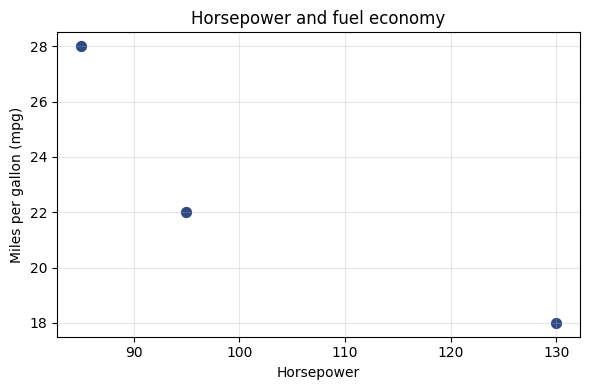

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(horsepower_demo, mpg_three,
           color="#314887", s=50)
ax.set_xlabel("Horsepower")
ax.set_ylabel("Miles per gallon (mpg)")
ax.set_title("Horsepower and fuel economy")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(image_dir / "234-horsepower.pdf")
fig.savefig(image_dir / "234-horsepower.png", dpi=180)
display(fig)
plt.close(fig)


### 练习 2.29  修正绘图语法

要画重量与 mpg 的散点图，`plt.subplots(figsize(6,4))` 和 `clean[mpg]` 有什么问题？


**参考答案**

前者应为 `plt.subplots(figsize=(6,4))`；后者应为 `clean["mpg"]`，因为列名是字符串。横坐标取 `clean["weight"]`，纵坐标取 `clean["mpg"]`。表格在2.3.7创建后即可这样画图。



## 2.3.5 序列与切片（Sequences and Slice Notation）


### 代码 2.3.5-01：读取单个元素与矩形切片

`X[0,0]` 是第一行第一列；`X[1,2]` 是第二行第三列。`1:3` 取索引1、2两行，`:2` 取索引0、1两列；因此最后输出一个 $(2,2)$ 的矩阵。

### 逐步读代码

- 此处重新给`X`赋值，旧的三行两列数组被这个四行三列数组替代。后面的索引均针对新`X`。

- 索引从0开始，`X[0,0]`取第一行第一列，`X[1,2]`取第二行第三列。

- `1:3`取位置1、2，`:2`取位置0、1；切片包含起点、不包含终点，所以结果是两行两列。

In [13]:
X = np.array([
    [100.0, 20.0, 10.0],
    [150.0, 10.0, 30.0],
    [80.0, 30.0, 20.0],
    [120.0, 40.0, 40.0],
])
print(X[0, 0])
print(X[1, 2])
print(X[1:3, :2])


100.0
30.0
[[150.  10.]
 [ 80.  30.]]


### 代码 2.3.5-02：取一列时保留几个轴？

冒号单独出现表示这一轴全部取出。用整数 `1` 选中一列会去掉列轴，结果形状 $(4,)$；用切片 `1:2` 保留列轴，结果 $(4,1)$。

### 逐步读代码

- 第一处冒号表示全部行，整数`1`指定第二列；`X[:,1]`去掉列轴，返回`(4,)`。

- `1:2`虽然也只选第二列，但它是切片，会保留列轴，因此`X[:,1:2]`返回`(4,1)`。两次打印形状用来确认接口需要哪一种表示。

In [14]:
print(X[:, 1])
print(X[:, 1].shape)
print(X[:, 1:2])
print(X[:, 1:2].shape)


[20. 10. 30. 40.]
(4,)
[[20.]
 [10.]
 [30.]
 [40.]]
(4, 1)


### 练习 2.30  切片边界

上面的 $X$ 中，`X[1:3, :2]` 取了哪些行和列？`X[:, 1]` 与 `X[:, 1:2]` 数值相同，为什么形状不同？


**参考答案**

取第二、三行和第一、二列。整数索引减少一个轴，切片保留这个轴，因此后两者分别为 $(4,)$ 和 $(4,1)$。



## 2.3.6 数据索引（Indexing Data）


### 代码 2.3.6-01：用同一个 mask 筛选 X 与 y

`mask` 的第 $i$ 个布尔值对应原数据第 $i$ 行。预算120也满足条件，所以第四个值是 `True`；保留第1、2、4行。`X` 与 `y` 必须使用同一个筛选条件，才能保持同一市场的特征和结果对应。这里补齐手稿中未给出的目标数组定义。

### 逐步读代码

- `X[:,0]>=100`对每个样本的第一列作比较，生成长度4的布尔掩码，真表示保留，假表示排除。

- `X[mask,:]`按掩码选行并保留所有列；`y[mask]`使用同一个掩码选目标，确保两者仍一一对应。

- 本例保留第1、2、4行，得到`(3,3)`的输入和`(3,)`的目标；`print`依次检查掩码、数据及形状。

In [15]:
y = np.array([11.0, 12.0, 11.2, 13.8])
mask = X[:, 0] >= 100
X_selected = X[mask, :]
y_selected = y[mask]
print(mask)
print(X_selected)
print(y_selected)
print(X_selected.shape, y_selected.shape)


[ True  True False  True]
[[100.  20.  10.]
 [150.  10.  30.]
 [120.  40.  40.]]
[11.  12.  13.8]
(3, 3) (3,)


### 代码 2.3.6-02：核对筛选前后的统计口径

前者对四个市场求均值，后者只对三个满足条件的市场求均值。二者回答的是不同人群的问题，不能只看到“均值”两个字就互换。

### 逐步读代码

- 两次`.mean(axis=0)`都逐列计算均值，但前者使用全部四行，后者只使用筛选后的三行。

- 分别保存到两个变量，避免覆盖原均值。打印结果的差异说明筛选改变了样本组成，不能把筛选后统计量当成全体统计量。

In [16]:
feature_means = X.mean(axis=0)
selected_means = X_selected.mean(axis=0)
print(feature_means)
print(selected_means)


[112.5  25.   25. ]
[123.33333333  23.33333333  26.66666667]


### 练习 2.31  按第二列筛选

在本节四行数据中，选择第二列不小于30的样本，并说明 $X$ 和 $y$ 的结果形状。


**参考答案**

先写 `mask = X[:, 1] >= 30`，再写 `X_selected = X[mask, :]` 和 `y_selected = y[mask]`。保留第三、四行，形状分别是 $(2,3)$ 与 $(2,)$。变量名大小写须一致，`x_selected` 与 `X_selected` 是两个名字。



## 2.3.7 读取数据（Loading Data）


### 代码 2.3.7-01：准备 CSV 文本

三引号允许字符串跨多行。第一行是列名，后面每行是一辆汽车，逗号分隔字段。这里的问号表示缺失。`StringIO` 让这一段文字像文本文件一样被读取。

### 逐步读代码

- `from io import StringIO`导入“把字符串当作文件读取”的工具，下一块会用到。

- 三引号允许CSV文本换行；首行写列名，其余每行是一辆车。问号此时只是文本字符，必须在读取时显式声明为缺失标记。

In [17]:
from io import StringIO

csv_text = """name,horsepower,weight,mpg
car_A,130,3500,18
car_B,?,2800,24
car_C,95,3000,22
car_D,110,?,20
car_E,70,2000,?
car_F,85,2400,28
"""


### 代码 2.3.7-02：读取并查看结构

`na_values=["?"]` 告诉 pandas 把问号识别为缺失值。`head()` 默认看前五行；`shape` 是整张表的行列数，不是刚打印的五行。`dtypes` 按列显示类型。实际读取磁盘 CSV 时，可把 `StringIO(csv_text)` 换成文件路径。

### 逐步读代码

- `StringIO(csv_text)`把文本包装成可读取对象，`pd.read_csv`解析逗号分隔字段；`na_values=["?"]`把问号转换为缺失值。

- `head()`默认查看前五行，不会删掉第六行；`.shape`仍报告完整表的行列数。

- `.columns`保存列标签，`.tolist()`把它转成普通列表；`.dtypes`按列显示类型，用来发现本应为数值的列是否被读成了文字。

In [18]:
df = pd.read_csv(StringIO(csv_text), na_values=["?"])
print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)


    name  horsepower  weight   mpg
0  car_A       130.0  3500.0  18.0
1  car_B         NaN  2800.0  24.0
2  car_C        95.0  3000.0  22.0
3  car_D       110.0     NaN  20.0
4  car_E        70.0  2000.0   NaN
(6, 4)
['name', 'horsepower', 'weight', 'mpg']
name           object
horsepower    float64
weight        float64
mpg           float64
dtype: object


### 代码 2.3.7-03：检查非缺失数量与缺失位置

`info()` 汇总每列非缺失数量与类型；`isna()` 返回与原表同形状的布尔表，缺失位置为真。布尔值求和时，真记1、假记0，沿 `axis=0` 汇总得到每列缺失数。

### 逐步读代码

- `info()`直接打印每列的非缺失数量与类型，不必再套`print`。

- `isna()`生成同形状布尔表，缺失位置为真；`.sum(axis=0)`按列汇总，真按1、假按0计数，得到每列缺失数量。

- `missing_counts`是一维Series，它的索引是列名，值是各列缺失数。

In [19]:
df.info()
print(df.isna())
missing_counts = df.isna().sum(axis=0)
print(missing_counts)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        6 non-null      object 
 1   horsepower  5 non-null      float64
 2   weight      5 non-null      float64
 3   mpg         5 non-null      float64
dtypes: float64(3), object(1)
memory usage: 320.0+ bytes
    name  horsepower  weight    mpg
0  False       False   False  False
1  False        True   False  False
2  False       False   False  False
3  False       False    True  False
4  False       False   False   True
5  False       False   False  False
name          0
horsepower    1
weight        1
mpg           1
dtype: int64


### 代码 2.3.7-04：先清洗整表，再分离特征和目标

`subset` 指定只检查这三列；`dropna` 删除其中有缺失的行。`copy()` 为后续处理创建副本。本例保留 A、C、F，原行标签0、2、5仍然保留，没有自动重新编号。

### 逐步读代码

- `feature_columns`是两个列名组成的列表，`target_column`是一个字符串；`[target_column]`把字符串包成单元素列表，才能与特征列表用`+`连接。

- `dropna(subset=required_columns)`只检查指定三列，只要其中一列缺失便删除该行；其他未指定列不参与判断。

- `.copy()`取得独立副本用于后续操作；原始`df`仍保留。打印`clean`核对留下的车辆和原始行标签。

In [20]:
feature_columns = ["horsepower", "weight"]
target_column = "mpg"
required_columns = feature_columns + [target_column]
clean = df.dropna(subset=required_columns).copy()
print(clean)


    name  horsepower  weight   mpg
0  car_A       130.0  3500.0  18.0
2  car_C        95.0  3000.0  22.0
5  car_F        85.0  2400.0  28.0


### 代码 2.3.7-05：loc 与 iloc：标签和位置

`loc[2,"horsepower"]` 根据标签找到原第2号行，也就是 car\_C，得到95。`iloc[2,1]` 根据当前位置取第三行、第二列，得到 car\_F 的85。单列字符串选择得到一维 Series；包含一个列名的列表选择得到二维 DataFrame。

### 逐步读代码

- `loc[2,"horsepower"]`按行标签2查找，再选马力列；`iloc[2,1]`按当前位置取第三行、第二列，两者的2含义不同。

- `clean["horsepower"]`用字符串选一列，得到Series；`clean[["horsepower"]]`用列表选列，得到单列DataFrame。

- 二者分别为`(3,)`与`(3,1)`，打印形状帮助区分一维目标与二维输入。

In [21]:
print(clean.loc[2, "horsepower"])
print(clean.iloc[2, 1])
horsepower_series = clean["horsepower"]
horsepower_table = clean[["horsepower"]]
print(horsepower_series.shape)
print(horsepower_table.shape)


95.0
85.0
(3,)
(3, 1)


### 代码 2.3.7-06：转换为建模数组

这里 $X$ 为三行两列，$y$ 为长度3的一维数组。两者从同一个 `clean` 按相同行顺序提取，样本一一对应。`target_column` 是单个字符串；若改成只含它的列表，结果会保留二维形状。

### 逐步读代码

- `clean[feature_columns]`按列表顺序选两列；`clean[target_column]`取一列目标。它们来自同一张表，保留相同样本顺序。

- `.to_numpy(dtype=float)`转成浮点NumPy数组，不再携带表格行标签和列名。分别得到`(3,2)`与`(3,)`，所以转换前应先确认对齐。

In [22]:
X = clean[feature_columns].to_numpy(dtype=float)
y = clean[target_column].to_numpy(dtype=float)
print(X)
print(y)
print(X.shape, y.shape)


[[ 130. 3500.]
 [  95. 3000.]
 [  85. 2400.]]
[18. 22. 28.]
(3, 2) (3,)


### 代码 2.3.7-07：按重量筛选表格

DataFrame 的列用列名字符串选择。`clean[:, "weight"]` 不是这里的合法写法；这是把 NumPy 二维切片语法误套到表格上。使用带索引的布尔 Series 时，`loc` 是清晰的选行方式，先选表格再拆分，保留 C 和 F。

### 逐步读代码

- `clean["weight"]<=3000`得到带行标签的布尔Series；`loc[mask]`按这些标签保留符合条件的记录，`.copy()`保存副本。

- 先筛选整表再选特征和目标，可以避免两边留下不同车辆。本例保留C、F，两个特征对应`(2,2)`，目标为`(2,)`。

In [23]:
mask = clean["weight"] <= 3000
selected = clean.loc[mask].copy()
X_selected = selected[feature_columns]
y_selected = selected[target_column]
print(selected)
print(X_selected.shape, y_selected.shape)


    name  horsepower  weight   mpg
2  car_C        95.0  3000.0  22.0
5  car_F        85.0  2400.0  28.0
(2, 2) (2,)


### 练习 2.32  分别删除缺失行会发生什么？

若分别对特征和目标删缺失，特征保留 A、C、E、F，目标保留 A、B、C、D、F，这样能直接训练吗？


**参考答案**

不能。行数不同，样本身份也不对应。应先在包含特征与目标的同一张表上按所需列统一处理，再提取两者。本例统一删行后保留 A、C、F。


### 练习 2.33  重量筛选与形状

筛选 `weight <= 3000` 后，$X$、$y$ 的形状是什么？为什么不把 `mask` 直接写进 `iloc`？


**参考答案**

保留 C、F，两项特征，所以形状分别为 $(2,2)$ 与 $(2,)$。本例 `mask` 是带行标签的 pandas 布尔 Series，使用 `loc[mask]`；`iloc` 是按整数位置索引的接口，不直接接受这种带标签布尔 Series。



## 2.3.8 for 循环（For Loops）


### 代码 2.3.8-01：依次计算每列均值

`for` 行末要有冒号；下一层代码统一缩进四个空格。第一次循环 `column` 为字符串 `"horsepower"`，接着是 `"weight"`，最后是 `"mpg"`。

### 逐步读代码

- `numeric_columns`保存要处理的列名。`for column in numeric_columns:`每轮把一个列名赋给`column`，行末冒号开启循环体。

- 缩进四个空格的两行每轮都会执行：取出该列、求均值并打印。循环结束后`mean_value`只保留最后一轮的值，不是所有均值的列表。

In [24]:
numeric_columns = ["horsepower", "weight", "mpg"]
for column in numeric_columns:
    mean_value = clean[column].mean()
    print(column, mean_value)


horsepower 103.33333333333333
weight 2966.6666666666665
mpg 22.666666666666668


### 代码 2.3.8-02：控制打印格式与查看范围

在字符串前加 `f`，花括号中的表达式会替换为结果。`:.2f` 表示显示两位小数，仅改变显示方式，不改变原始数据或计算精度。第二个循环分别取得每列的最小值和最大值。

### 逐步读代码

- `f"{column}: {mean_value:.2f}"`是格式化字符串：花括号放变量，`:.2f`要求显示两位小数，不修改原始数据。

- 第二个循环重新遍历列名，`.min()`和`.max()`分别取该列最小、最大值；输出顺序是列名、最小值、最大值。

In [25]:
for column in numeric_columns:
    mean_value = clean[column].mean()
    print(f"{column}: {mean_value:.2f}")

for column in numeric_columns:
    min_value = clean[column].min()
    max_value = clean[column].max()
    print(column, min_value, max_value)


horsepower: 103.33
weight: 2966.67
mpg: 22.67
horsepower 85.0 130.0
weight 2400.0 3500.0
mpg 18.0 28.0


### 练习 2.34  循环变量代表什么？

上述循环中的 column 是一列数值，还是一个列名？若输出均值保留两位小数，原始值是否被修改？


**参考答案**

它是列名字符串；`clean[column]` 才取出那一列数据。格式化输出不修改原值，例如 $22.666\ldots$ 显示为22.67，原对象仍保留其数值精度。



## 2.3.9 更多图形与数值汇总（Additional Graphical and Numerical Summaries）


### 代码 2.3.9-01：describe 汇总各列

`count` 是非缺失数量，`mean` 是均值，`std` 是标准差，`min/max` 是最小值和最大值，25%、50%、75% 是分位数。这里只含三辆完整汽车；这些统计量描述的是这三行，不是原来六行，更不是汽车总体。

### 逐步读代码

- `describe()`对选定数值列返回计数、均值、标准差、四分位数和极值。它的结果仍是DataFrame，可存到`summary`继续使用。

- `summary.round(3)`返回显示为三位小数的结果，供打印阅读；没有重新赋值，所以`summary`仍保留原精度。

In [26]:
summary = clean[numeric_columns].describe()
print(summary.round(3))


       horsepower    weight     mpg
count       3.000     3.000   3.000
mean      103.333  2966.667  22.667
std        23.629   550.757   5.033
min        85.000  2400.000  18.000
25%        90.000  2700.000  20.000
50%        95.000  3000.000  22.000
75%       112.500  3250.000  25.000
max       130.000  3500.000  28.000


### 代码 2.3.9-02：标准差分母：n 还是 n-1？

手稿强调 pandas 与 NumPy 的默认值不同。设有 $n$ 个非缺失值，NumPy 的计算为

$$s_{\mathrm{ddof}}=\sqrt{\frac{\sum_{i=1}^n(y_i-\bar y)^2}{n-\mathrm{ddof}}}.$$

`np.std` 默认 `ddof=0`，分母为 $n$；pandas 的 `Series.std()` 默认 `ddof=1`，分母为 $n-1$。本例指定相同 `ddof` 后，结果一致。注意 `to_numpy()` 末尾的括号不可省略。

### 逐步读代码

- `.to_numpy()`把mpg列变为数组，三次计算使用同一组数。

- `ddof`控制标准差分母：分母为样本数减`ddof`，0对应除以n，1对应除以n-1。NumPy默认0，pandas的Series默认1，因此应对齐这个设置再比较。

In [27]:
values = clean["mpg"].to_numpy()
print(np.std(values, ddof=0))
print(np.std(values, ddof=1))
print(clean["mpg"].std())


4.109609335312651
5.033222956847167
5.033222956847167


### 代码 2.3.9-03：准备分布演示数据

这组数据中45明显高于其他值，但现在只是一个需要进一步查看的数，不先判定为录入错误。

### 逐步读代码

- `pd.Series`创建带索引的一维数据，`name="mpg"`给这列数据命名；没有指定索引时使用从0开始的整数标签。

- `.to_list()`转成普通列表供打印。这12个数用于说明分布，不是前面清洗后的三辆车，也不是下载的真实Auto记录。

In [28]:
mpg_demo = pd.Series(
    [15, 18, 19, 20, 21, 22, 23, 24, 26, 28, 30, 45],
    name="mpg",
)
print(mpg_demo.to_list())


[15, 18, 19, 20, 21, 22, 23, 24, 26, 28, 30, 45]


### 代码 2.3.9-04：直方图：按区间计数

直方图先划分区间，再统计每个区间有多少条记录，用柱高表示数量。五个边界形成四个区间：$[10,20)$、$[20,30)$、$[30,40)$、$[40,50]$。除最后一个区间包含右端点外，均左闭右开。例如20计入第二个区间，30计入第三个。

### 逐步读代码

- `bins`给的是区间边界而非区间个数；五个边界划出四个区间。

- `ax.hist`同时返回三个对象，依次赋给`counts`、`edges`、`patches`：各箱频数、边界数组、用于画柱子的图形对象。

- `edgecolor`指定柱子边线，`color`指定内部颜色；坐标轴分别标出mpg和数量。`counts.astype(int)`把计数显示为整数，而不改变原始mpg。

- 两次`savefig`保存图，`display`展示，`close`释放对象；最后一个区间包含最右边界，其余区间右端不含。

[3 7 1 1]


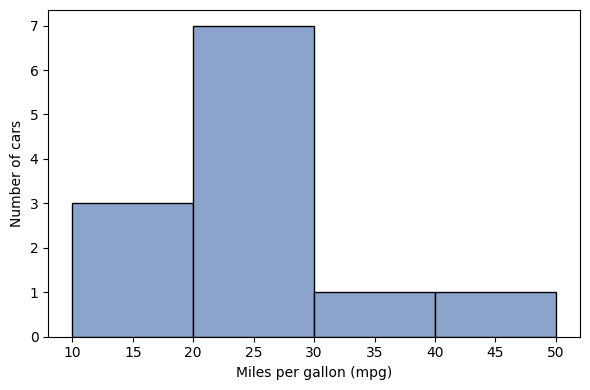

In [29]:
bins = [10, 20, 30, 40, 50]
fig, ax = plt.subplots(figsize=(6, 4))
counts, edges, patches = ax.hist(
    mpg_demo, bins=bins, edgecolor="black", color="#8CA3CC"
)
ax.set_xlabel("Miles per gallon (mpg)")
ax.set_ylabel("Number of cars")
fig.tight_layout()
fig.savefig(image_dir / "239-hist.pdf")
fig.savefig(image_dir / "239-hist.png", dpi=180)
print(counts.astype(int))
display(fig)
plt.close(fig)


### 代码 2.3.9-05：箱线图：概括位置与分散程度

箱体下边界是第一四分位数 $Q_1$，中间线是中位数，上边界是第三四分位数 $Q_3$。箱高 $\mathrm{IQR}=Q_3-Q_1$。默认“须”延伸到 $[Q_1-1.5\mathrm{IQR},Q_3+1.5\mathrm{IQR}]$ 内最远的实际观测值，通常不恰好等于这两个界限。界限外的点单独标记。

### 逐步读代码

- `boxplot(mpg_demo)`用同一列数画箱线图；轴名、标题和保存操作与前面的散点图相同。

- `quantile([0.25,0.5,0.75])`按顺序返回三个分位数，再由`q1, median, q3 = ...`分别接收。

- `iqr=q3-q1`是四分位距；打印的两道界限是Q1减1.5倍IQR、Q3加1.5倍IQR。它们是判断箱外点的阈值，不一定是图上须线的实际端点。

19.75 22.5 26.5
9.625 36.625


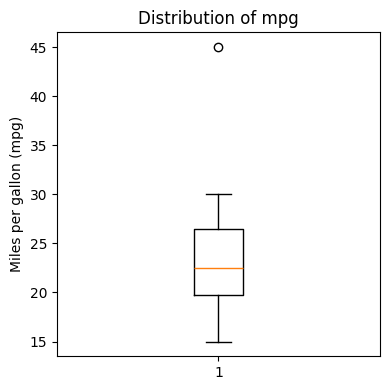

In [30]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(mpg_demo)
ax.set_ylabel("Miles per gallon (mpg)")
ax.set_title("Distribution of mpg")
fig.tight_layout()
fig.savefig(image_dir / "239-box.pdf")
fig.savefig(image_dir / "239-box.png", dpi=180)
q1, median, q3 = mpg_demo.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
print(q1, median, q3)
print(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
display(fig)
plt.close(fig)


### 代码 2.3.9-06：创建十二辆汽车的数据表

这里 $X$ 保持为二维 DataFrame，$y$ 保持为一维 Series。scikit-learn 可以直接接收它们，列名也可保留下来。名字或编号不在这两个输入特征中。

### 逐步读代码

- 花括号创建字典，键是列名，值是每列的列表；`pd.DataFrame`把各列按相同位置组成12行表格，各列表长度必须一致。

- 特征列表选出马力、重量两列，目标字符串只选mpg列，分别得到`(12,2)`和`(12,)`。

- 这些车辆数据是专门构造的教学样本，后续分数用于演示流程，不能当成实际业务效果。

In [31]:
cars_demo = pd.DataFrame({
    "horsepower": [160, 145, 135, 125, 115, 110,
                   105, 100, 90, 85, 75, 60],
    "weight": [4000, 3700, 3500, 3300, 3100, 3000,
               2900, 2800, 2600, 2400, 2200, 1800],
    "mpg": [15, 18, 19, 20, 21, 22,
            23, 24, 26, 28, 30, 45],
})
feature_columns = ["horsepower", "weight"]
target_column = "mpg"
X = cars_demo[feature_columns]
y = cars_demo[target_column]
print(X.shape, y.shape)


(12, 2) (12,)


### 代码 2.3.9-07：先保留一份测试数据

必须把 $X$ 和 $y$ 一起传入，才会用同一组行索引划分。`test_size=0.25` 留出25%，本例训练9辆、测试3辆。`random_state=42` 便于重现本次随机划分；它不保证这一划分具有代表性。

### 逐步读代码

- `train_test_split(X,y,...)`使用同一套行划分同时拆分输入与目标；左边四个变量的顺序必须与返回顺序对应。

- `test_size=0.25`留出四分之一的行，`random_state=42`固定随机划分以便复现；12行得到9行训练、3行测试。

- `.index.to_list()`打印原行标签，帮助检查哪些车辆分到哪组。标签保留原样，不会因随机划分重新编号。

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(len(X_train), len(X_test))
print(X_train.index.to_list())
print(X_test.index.to_list())


9 3
[8, 5, 2, 1, 11, 4, 7, 3, 6]
[10, 9, 0]


### 代码 2.3.9-08：用训练均值建立基准

`mean()` 只能从训练目标计算；不能用测试集答案来选择预测值。`np.full` 创建指定形状的数组，并把每个位置填成同一个数。测试集三辆汽车，因此要给出三个预测。

### 逐步读代码

- `y_train.mean()`只用训练目标学习一个平均值，保存为`baseline_value`。

- `np.full(shape=...,fill_value=...)`创建指定形状、所有位置都相同的数组；`len(X_test)`等于测试车辆数，因此每辆车都得到同一个训练均值预测。

In [33]:
baseline_value = y_train.mean()
baseline_pred = np.full(
    shape=len(X_test), fill_value=baseline_value
)
print(baseline_value)
print(baseline_pred)
print(baseline_pred.shape)


24.22222222222222
[24.22222222 24.22222222 24.22222222]
(3,)


### 代码 2.3.9-09：计算基准的测试误差

现在才用测试集目标核对预测：先逐个相减，再平方，再平均。这些标签用于评估，不能回过头参与基准值的计算。MSE 的单位是 mpg 的平方。

### 逐步读代码

- `y_test.to_numpy()`取得按测试行顺序排列的真实目标数组；与同顺序的基准预测逐项相减。

- `errors**2`先平方，`np.mean`再平均。打印残差用于观察方向，打印MSE用于衡量总体平方误差，二者用途不同。

In [34]:
y_test_array = y_test.to_numpy()
errors = y_test_array - baseline_pred
baseline_test_mse = np.mean(errors ** 2)
print(errors)
print(baseline_test_mse)


[ 5.77777778  3.77777778 -9.22222222]
44.23456790123456


### 代码 2.3.9-10：创建并训练线性回归

`LinearRegression()` 创建模型对象，`fit(X_train,y_train)` 从训练数据估计参数。`intercept_` 是截距，`coef_` 的两个系数依次对应马力和重量。

$$\widehat{\mathrm{mpg}}=\widehat\beta_0+\widehat\beta_1\mathrm{horsepower}+\widehat\beta_2\mathrm{weight}.$$

线性形式由我们指定，系数由训练数据确定。如何求出最小二乘系数将在第三章严格推导。

### 逐步读代码

- 导入并调用`LinearRegression()`创建模型，再用训练输入和训练目标调用`fit`。

- `.intercept_`是一个截距，`.coef_`中的两个数依次对应马力与重量；顺序由`feature_columns`决定，不能交换解释。

In [35]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
print(model.intercept_)
print(model.coef_)


99.8893280632411
[ 1.40197628 -0.07722661]


### 代码 2.3.9-11：预测并核对测试 MSE

`predict` 只接收新汽车的特征，使用已经学好的参数给出预测。误差表达式的括号必须覆盖整个平方差：`mean((真实 - 预测) ** 2)`，不是先求误差均值再平方。
模型系数可能不符合“单独增加马力”的直觉，因为这里的马力和重量高度相关，且样本很少。系数也不能自动解释成因果效应。

### 逐步读代码

- `predict(X_test)`只接收输入特征；真实测试目标不参与生成预测。

- 括号让MSE表达式跨多行书写，数学含义仍是先相减、平方、求均值。分别打印预测数组与一个MSE标量。

In [36]:
y_pred_linear = model.predict(X_test)
linear_test_mse = np.mean(
    (y_test_array - y_pred_linear) ** 2
)
print(y_pred_linear)
print(linear_test_mse)


[35.13899868 33.71343874 15.29907773]
19.714045710007213


### 代码 2.3.9-12：检查训练残差

MSE 把所有误差压缩成一个数；残差 $e_i=y_i-\widehat y_i$ 保留方向。正残差说明低估，负残差说明高估。这里看训练残差用于发现问题，不能把训练表现当成新数据表现。

### 逐步读代码

- 这里把训练输入送回已经拟合的模型，因此得到的是训练预测。真实训练目标转为数组后与预测按位置相减。

- `np.round(residual_train,3)`仅生成便于显示的三位小数；下一行MSE仍使用未舍入的`residual_train`，避免显示舍入影响计算。

In [37]:
y_train_pred = model.predict(X_train)
y_train_array = y_train.to_numpy()
residual_train = y_train_array - y_train_pred
print(np.round(residual_train, 3))
print(np.mean(residual_train ** 2))


[ 0.722 -0.427  0.137  0.563  0.    -0.714  0.148 -0.289 -0.14 ]
0.18591714243888172


### 代码 2.3.9-13：残差随汽车重量如何变化？

横轴是重量，纵轴是相应汽车的训练残差，水平虚线是零。观察残差是否有弯曲趋势、明显偏离或随重量增大而扩散。图形是诊断线索，不是模型假设已成立或已失效的严格证明。

### 逐步读代码

- 横轴取训练车辆重量，纵轴取同顺序的训练残差；这样可观察误差是否随重量系统变化。

- `axhline(y=0,linestyle="--")`在零残差处画水平虚线。线上方表示低估，下方表示高估；图中没有验证或测试残差。

- 设置轴名后保存两种格式，显示并关闭图。保存图不改变模型或训练数据。

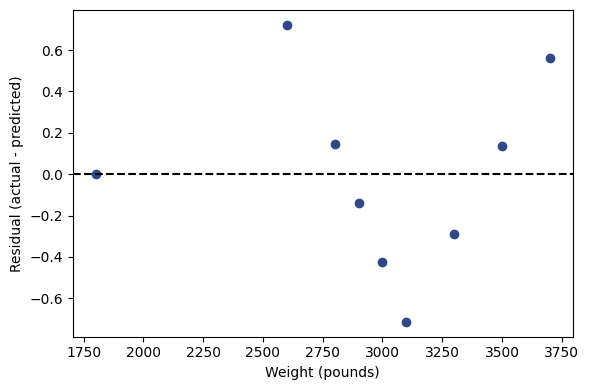

In [38]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_train["weight"], residual_train,
           color="#314887")
ax.axhline(y=0, color="black", linestyle="--")
ax.set_xlabel("Weight (pounds)")
ax.set_ylabel("Residual (actual - predicted)")
fig.tight_layout()
fig.savefig(image_dir / "239-residual.pdf")
fig.savefig(image_dir / "239-residual.png", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.3.9-14：从开发数据里再划出验证集

`dev` 是 development 的缩写。第一次从12行留出3行测试，剩9行开发；第二次从9行中留出三分之一，即3行验证，训练剩6行。第二次的比例以开发数据为基数，不是以最初12行为基数。

### 逐步读代码

- 第一次从全部12行留3行测试，剩9行开发；第二次仅在开发数据中取三分之一作验证，得到6行训练、3行验证。

- `set(X_train.index)`把训练行标签转为集合；`.isdisjoint(X_val.index)`判断两组标签是否无交集，返回一个布尔值。

- `assert`要求这个结果为真，否则报错；第二条断言检查开发与测试无交集。由于训练与验证都来自开发集，两条检查共同支持三组分离。

- 这种检查依赖行标签能标识样本；它不检查不同记录是否属于同一个客户或车型家族。本例也已见过这批测试结果，所以仍仅用于教学流程。

In [39]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=1/3, random_state=42
)
print(len(X_train), len(X_val), len(X_test))
print(X_train.index.to_list())
print(X_val.index.to_list())
print(X_test.index.to_list())
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)


6 3 3
[8, 6, 2, 11, 1, 7]
[3, 5, 4]
[10, 9, 0]


### 代码 2.3.9-15：在同一个训练集上拟合两个候选方法

两个候选方法都只学习训练数据。比较时预测同一批验证汽车，才能让两种误差有共同的比较对象。

### 逐步读代码

- 基准均值和线性系数都只从当前六行训练数据学习；不能沿用前面九行训练时的参数。

- `np.full`按验证样本数复制均值；线性模型用`predict(X_val)`生成另一组预测。两组数组顺序都与`y_val`一致。

In [40]:
baseline_value = y_train.mean()
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
baseline_val_pred = np.full(len(X_val), baseline_value)
linear_val_pred = linear_model.predict(X_val)
print(baseline_val_pred)
print(linear_val_pred)


[25.83333333 25.83333333 25.83333333]
[20.57777778 22.71111111 22.        ]


### 代码 2.3.9-16：计算验证误差并固定选择

当前选择标准预先设为验证 MSE 更低；若两者相同，代码选择简单基准。这一步不能同时查看测试结果来改变选择。`if ... else ...` 根据比较条件选取一个字符串，后面据此决定最终训练的方法。

### 逐步读代码

- 分别将同一份验证目标与两组预测比较，得到两个MSE；只有比较相同样本与指标才有意义。

- `"linear" if 条件 else "baseline"`是条件表达式：线性MSE严格更小时选线性，否则选基准，相等也走`else`。

- `chosen_method`保存方法名称字符串，不是已经重训的模型；下一块据此决定执行哪个分支。

In [41]:
y_val_array = y_val.to_numpy()
baseline_val_mse = np.mean(
    (y_val_array - baseline_val_pred) ** 2
)
linear_val_mse = np.mean(
    (y_val_array - linear_val_pred) ** 2
)
chosen_method = (
    "linear" if linear_val_mse < baseline_val_mse
    else "baseline"
)
print("baseline validation MSE:", baseline_val_mse)
print("linear validation MSE:", linear_val_mse)
print("chosen:", chosen_method)


baseline validation MSE: 24.027777777777768
linear validation MSE: 0.6131687242798307
chosen: linear


### 代码 2.3.9-17：固定方法后在全部开发数据上重训

选定方法后可以重新训练，让参数利用更多已用于开发的数据。若选线性回归，就重估系数；若选基准，就重算开发集均值。重新训练只用训练集与验证集合成的开发数据，不包含测试目标。

### 逐步读代码

- `if chosen_method == "linear":`比较方法名称；条件成立时只运行第一组缩进行，否则只运行`else`分支。

- 线性分支创建新模型并在全部开发数据重训；基准分支重新计算开发目标均值。重训会重新学习参数，保留的是此前选定的方法。

- 两个分支都生成同名`final_pred`，使下一块可以用统一代码评估；测试目标仍没有用于拟合。

In [42]:
if chosen_method == "linear":
    final_model = LinearRegression()
    final_model.fit(X_dev, y_dev)
    final_pred = final_model.predict(X_test)
else:
    final_mean = y_dev.mean()
    final_pred = np.full(len(X_test), final_mean)

print(chosen_method)
print(final_pred)


linear
[35.13899868 33.71343874 15.29907773]


### 代码 2.3.9-18：最终评估与逐车核对

这张表保留测试汽车的原行标签，逐车列出真实值、预测值和残差。最后的 MSE 是当前固定方法在三辆测试汽车上的误差，不是总体风险的精确值。不能看到分数后再调方法，并继续把同一分数称为独立最终评估。

### 逐步读代码

- 先计算最终残差与MSE，再用字典构造结果表；三列分别存真实值、预测、残差。

- `index=y_test.index`让每行保留车辆身份，便于回查。打印用`round(3)`简化显示，但`final_mse`用的是未舍入数值。

- 这张表可以查找个别预测，MSE概括总体；两者都不能把已经用于教学的测试样本重新变成未见数据。

In [43]:
final_errors = y_test.to_numpy() - final_pred
final_mse = np.mean(final_errors ** 2)
results = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": final_pred,
    "residual": final_errors,
}, index=y_test.index)
print(results.round(3))
print("final test MSE:", final_mse)


    actual  predicted  residual
10      30     35.139    -5.139
9       28     33.713    -5.713
0       15     15.299    -0.299
final test MSE: 19.714045710007213


### 练习 2.35  改变直方图区间

若改用边界 `[10, 25, 40, 55]`，本例三个区间的数量分别是多少？


**参考答案**

区间为 $[10,25)$、$[25,40)$、$[40,55]$，数量分别为8、3、1。分箱会改变展示方式，不改变原始数据。


### 练习 2.36  箱外的点与标准差

45被箱线图标记后是否必须删除？为什么 NumPy 与 pandas 默认标准差不相同？


**参考答案**

不必删除，应先核对数据与业务事实。两者默认标准差分母不同：NumPy用 $n$，pandas用 $n-1$；本例对同样非缺失数据指定相同 `ddof` 后结果一致。


### 练习 2.37  基准预测的手算检查

训练目标为18、22、26，测试目标为20、28。均值基准给出什么预测？测试 MSE 是多少？


**参考答案**

训练均值为 $(18+22+26)/3=22$，两个测试预测均为22。MSE为 $[(20-22)^2+(28-22)^2]/2=20$。基准仍然是从训练数据学习了一个参数，不能说它完全没有训练。


### 练习 2.38  系数、残差与接口

给定 $\widehat{\mathrm{mpg}}=50-0.05\mathrm{horsepower}-0.006\mathrm{weight}$，马力100、重量3000的预测是什么？重量增加200且马力不变，预测如何变？真实值为30时残差是多少？


**参考答案**

预测是 $50-5-18=27$；变化为 $-0.006\times200=-1.2$；残差为 $30-27=3$，说明低估。实际调用时用训练 $X,y$ 拟合，用测试 $X$ 预测，再用测试 $y$ 计算误差，三步不能混淆。


### 练习 2.39  三份划分

1000行数据先留20%测试，再从开发数据留25%验证，训练、验证、测试各多少行？为何第二次不能按1000算？


**参考答案**

测试200行，开发800行；验证 $800\times0.25=200$ 行，训练600行。第二次输入的是开发数据。验证误差用于选择；反复根据测试结果改模型，会让测试集参与开发。


### 练习 2.40  预测误差的方向

真实值减预测值得到 $-2,0,4$。哪条高估、哪条低估？MSE是多少？


**参考答案**

第一条残差负，预测偏高；第三条残差正，预测偏低。MSE为 $(4+0+16)/3=20/3$。残差均值会正负抵消，不能替代MSE。

